# Horizontal TDOA Voting vs Beamforming

In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code") 

from HATS_functions import gcc_phat, corr_to_itd

height = "H2"

angles = ["-45", "0", "+45"]
PathToFiles = f"../Audio_Files/Real_World_Measurements/Vertical/{height}"

num_mics = 7
angle_increment = 360/num_mics
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Vert 1-Audio.wav",
                '1': folder / "Vert 2-Audio.wav",
                '2': folder / "Vert 3-Audio.wav",
                '3': folder / "Vert 4-Audio.wav",
                '4': folder / "Vert 5-Audio.wav",
                '5': folder / "Vert 6-Audio.wav",
                '6': folder / "Vert 7-Audio.wav",
                '7': folder / "Vert 8-Audio.wav"
            }
    else:
    
        print(f"Missing folder: {folder}")

In [2]:
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def plot_array_voting(scores, true_source_deg, save_path=None):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    max_score = max(scores.values())

    # Outer mics
    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        size = 200 + 800 * intensity
        color = cm.Blues(0.3 + 0.7 * intensity)

        ax.scatter(a, mic_r, s=size, color=color, zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 1.15), ha='center', fontsize=9)

    # Centre mic
    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    size_c = 200 + 800 * intensity_c
    color_c = cm.Blues(0.3 + 0.7 * intensity_c)

    ax.scatter(0, 0, s=size_c, color=color_c, zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)

    # Winning sector 
    outer_scores = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer_scores.items(), key=lambda x: -x[1])
    winning_mic = int(sorted_mics[0][0])
    second_mic = int(sorted_mics[1][0])

    a1 = mic_angles_deg[winning_mic - 1]
    a2 = mic_angles_deg[second_mic - 1]

    delta = ((a2 - a1 + 180) % 360) - 180

    if delta >= 0:
        sector_start = np.radians(a1)
        sector_end = np.radians(a1 + delta)
    else:
        sector_start = np.radians(a1 + delta)
        sector_end = np.radians(a1)

    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='steelblue',
                label='Estimated sector')

    # Array
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # True source
    source_angle_rad = np.radians(true_source_deg)
    source_r = 0.08
    ax.plot([source_angle_rad, source_angle_rad], [0, source_r],
            color='coral', lw=2)
    ax.plot(source_angle_rad, source_r, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'DOA — Array TDOA Voting Estimate ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()

    if save_path:
        fig.savefig(f"{save_path}.png", dpi=200, bbox_inches='tight')
        fig.savefig(f"{save_path}.pdf", bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [3]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

vote_results = {}

def compute_votes(source_angle_key):
    scores = {str(i): 0 for i in range(7)}
    for i in range(7):
        datax, fs = sf.read(recordings[source_angle_key][str(i)])
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings[source_angle_key][str(j)])
            correlation = gcc_phat(datax, datay)
            itd = corr_to_itd(correlation, dists[i][j], fs)
            if itd < 0:
                scores[str(i)] += 1
            else:
                scores[str(j)] += 1
    return scores


for source_angle in recordings.keys():
    scores = compute_votes(source_angle)
    vote_results[source_angle] = scores
    #plot_array_voting(scores, float(source_angle), figures_dir / f"array_voting_{source_angle}")

In [4]:
from pathlib import Path
import pyroomacoustics as pra
import numpy as np
import soundfile as sf

# Mic positions 
r = 0.045
mic_angles_deg = [0, 60, 120, 180, 240, 300]

positions = [[0, 0, 0]]
for a in mic_angles_deg:
    theta = np.radians(a)
    positions.append([0, -r * np.sin(theta), r * np.cos(theta)])

mic_positions = np.array(positions).T

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')
    
def plot_srp_doa(doa, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    for a in mic_angles_rad:
        ax.scatter(a, mic_r, s=200, color=cm.Blues(0.6), zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
    ax.scatter(0, 0, s=200, color=cm.Blues(0.6), zorder=5,
               edgecolors='steelblue', linewidths=1.5)

    for a, label in zip(mic_angles_rad, range(1, 7)):
        ax.annotate(f'Mic {label}', (a, mic_r * 1.15), ha='center', fontsize=9)

    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # SRP-PHAT spectrum 
    azimuth = doa.grid.azimuth
    spectrum = doa.grid.values
    spectrum_norm = spectrum / spectrum.max()

    spectrum_r_min = 0.005
    spectrum_r_max = mic_r * 0.9
    spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

    ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4,
                    color='steelblue', label='SRP-PHAT spectrum')
    ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

    # Estimated DOA
    estimated_rad = doa.azimuth_recon[0]
    estimated_deg = np.degrees(estimated_rad)
    ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue',
            linestyle='--', linewidth=2)
    ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10,
            label=f'Estimated ({estimated_deg:.1f}°)')

    # True source
    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'SRP-PHAT — Array DOA ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()

    save_fig(fig, name)
    plt.show()
    plt.close(fig)
    
def run_srp(source_angle_key):
    signals = []
    for i in range(7):
        data, fs = sf.read(recordings[source_angle_key][str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    doa = pra.doa.algorithms['SRP'](mic_positions, fs, nfft, c=343, num_src=1)
    doa.locate_sources(X)
    return doa

# Save
srp_results = {}
for angle_key in recordings.keys():
    print(f"SRP for {angle_key}°...")
    doa = run_srp(angle_key)
    srp_results[angle_key] = [np.degrees(doa.azimuth_recon[0]), doa]

SRP for -45°...
SRP for 0°...
SRP for +45°...


In [5]:
mic_positions

array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00],
       [ 0.00000000e+00, -0.00000000e+00, -3.89711432e-02,
        -3.89711432e-02, -5.51091060e-18,  3.89711432e-02,
         3.89711432e-02],
       [ 0.00000000e+00,  4.50000000e-02,  2.25000000e-02,
        -2.25000000e-02, -4.50000000e-02, -2.25000000e-02,
         2.25000000e-02]])

# Comparison Plots

True source: -45.0° → -0.785 rad = -45.0°


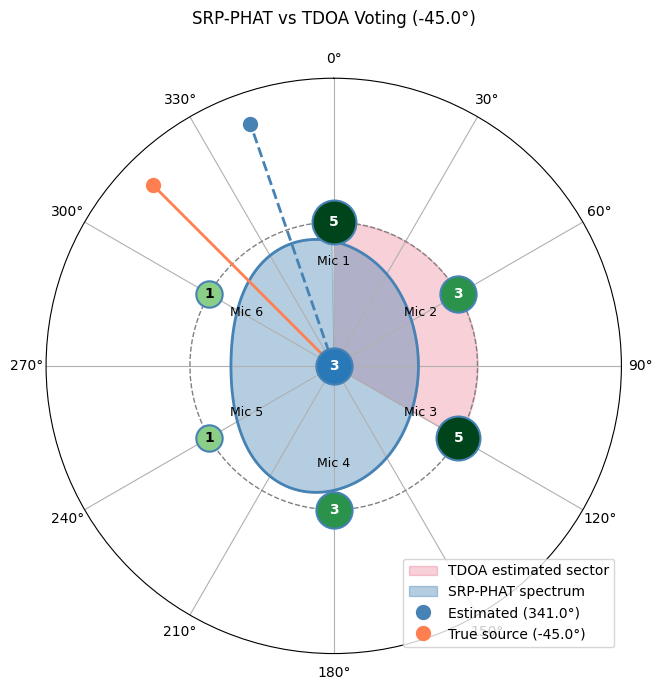

True source: 0.0° → 0.000 rad = 0.0°


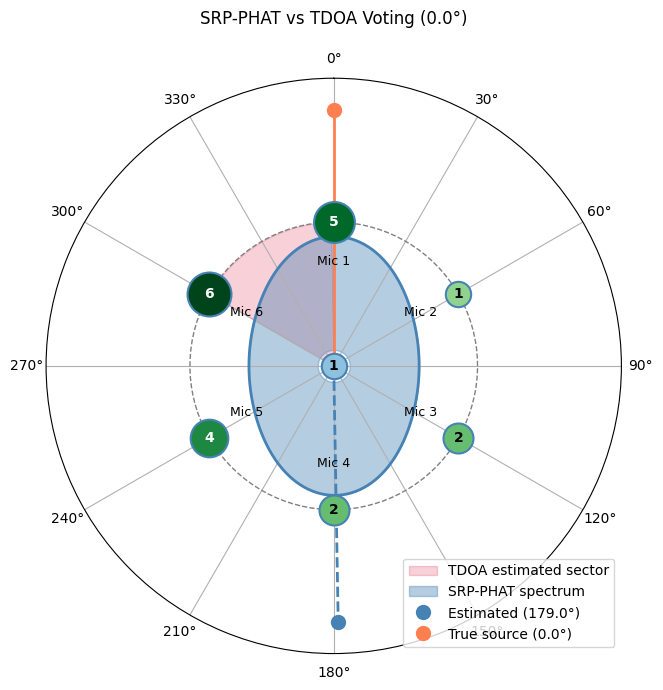

True source: 45.0° → 0.785 rad = 45.0°


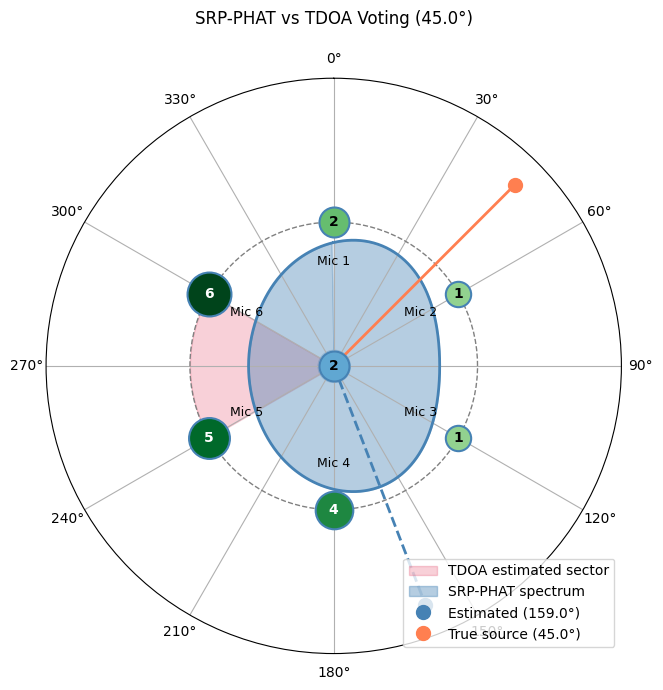

In [6]:
def plot_comparison(doa, scores, true_source_deg, name):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    
    
##### Voting
    max_score = max(scores.values())

    # Outer mics
    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        size = 200 + 800 * intensity
        color = cm.Greens(0.3 + 0.7 * intensity)

        ax.scatter(a, mic_r, s=size, color=color, zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 0.7), ha='center', fontsize=9)

    # Centre mic
    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    size_c = 200 + 800 * intensity_c
    color_c = cm.Blues(0.3 + 0.7 * intensity_c)

    ax.scatter(0, 0, s=size_c, color=color_c, zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)
    
    # Winning sector
    outer_scores = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer_scores.items(), key=lambda x: -x[1])
    winning_mic = int(sorted_mics[0][0])
    second_mic = int(sorted_mics[1][0])

    a1 = mic_angles_deg[winning_mic - 1]
    a2 = mic_angles_deg[second_mic - 1]

    delta = ((a2 - a1 + 180) % 360) - 180

    if delta >= 0:
        sector_start = np.radians(a1)
        sector_end = np.radians(a1 + delta)
    else:
        sector_start = np.radians(a1 + delta)
        sector_end = np.radians(a1)

    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='crimson',
                label='TDOA estimated sector')
    

##### SRP
    # SRP spectrum 
    azimuth = doa.grid.azimuth
    spectrum = doa.grid.values
    spectrum_norm = spectrum / spectrum.max()

    spectrum_r_min = 0.005
    spectrum_r_max = mic_r * 0.9
    spectrum_r = spectrum_r_min + (spectrum_r_max - spectrum_r_min) * spectrum_norm

    ax.fill_between(azimuth, spectrum_r_min, spectrum_r, alpha=0.4,
                    color='steelblue', label='SRP-PHAT spectrum')
    ax.plot(azimuth, spectrum_r, color='steelblue', linewidth=2)

    # Estimated DOA
    estimated_rad = doa.azimuth_recon[0]
    estimated_deg = np.degrees(estimated_rad)
    ax.plot([estimated_rad, estimated_rad], [0, 0.08], color='steelblue',
            linestyle='--', linewidth=2)
    ax.plot(estimated_rad, 0.08, 'o', color='steelblue', markersize=10,
            label=f'Estimated ({estimated_deg:.1f}°)')

    # Array boundary
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # True source
    source_angle_rad = np.radians(true_source_deg)
    ax.plot([source_angle_rad, source_angle_rad], [0, 0.08], color='coral', lw=2)
    ax.plot(source_angle_rad, 0.08, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'SRP-PHAT vs TDOA Voting ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower right')
    plt.tight_layout()
    
    print(f"True source: {true_source_deg}° → {source_angle_rad:.3f} rad = {np.degrees(source_angle_rad):.1f}°")

    save_fig(fig, name)
    plt.show()
    plt.close(fig)
    
    
for angle_key in recordings.keys():
    doa = srp_results[angle_key][1]
    scores = vote_results[angle_key]
    plot_comparison(doa, scores, float(angle_key), f"srp_{angle_key}")


--- H2 ---
  true az=   -45° → az= -19.0° (+26.0°)  el=  +2.0° ( +2.0°)
  true az=     0° → az=  +0.0° ( +0.0°)  el=  +2.0° ( +2.0°)
  true az=   +45° → az= +21.0° (-24.0°)  el=  +1.0° ( +1.0°)


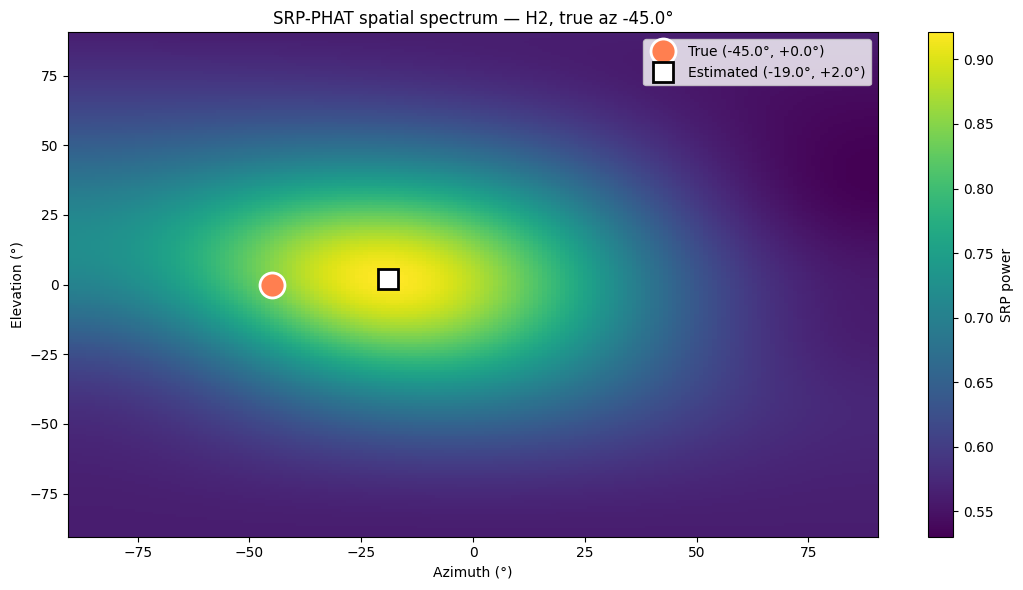

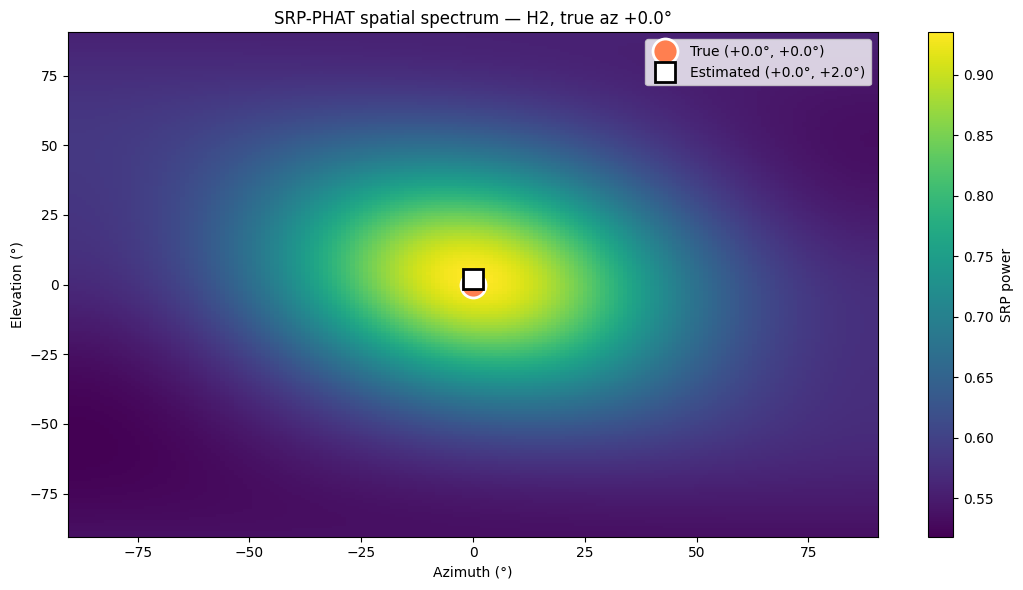

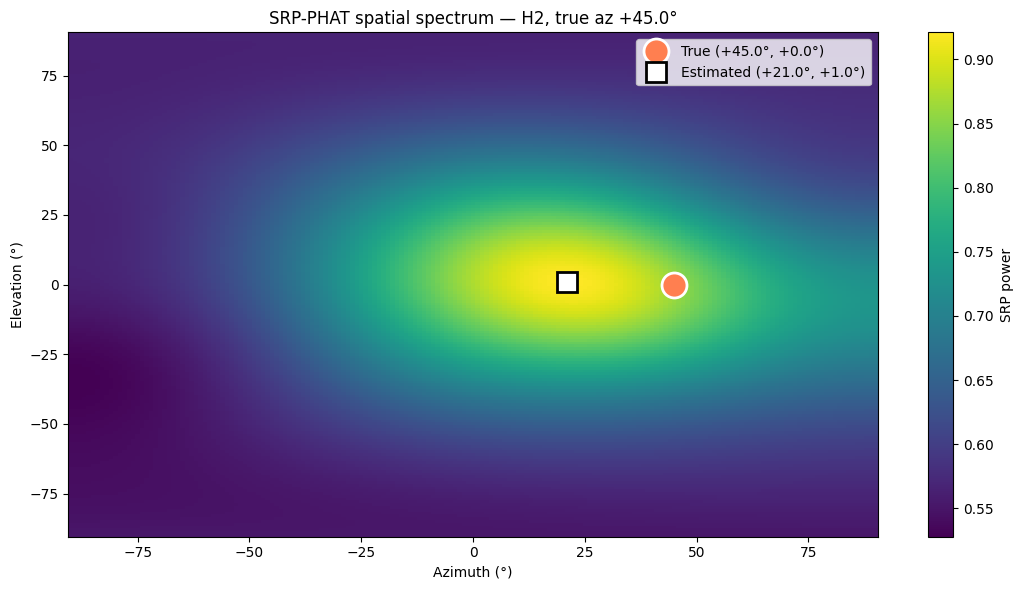

In [7]:
def run_srp_3d(recording_dict):
    signals = []
    for i in range(7):
        data, fs = sf.read(recording_dict[str(i)])
        if data.ndim > 1:
            data = data.mean(axis=1)
        signals.append(data)

    min_len = min(len(s) for s in signals)
    signals = np.stack([s[:min_len] for s in signals])

    nfft = 256
    hop = nfft // 2
    X = pra.transform.stft.analysis(signals.T, L=nfft, hop=hop)
    X = X.transpose(2, 1, 0)

    azimuth_grid = np.linspace(-np.pi/2, np.pi/2, 181)
    colatitude_grid = np.linspace(0, np.pi, 181)

    doa = pra.doa.algorithms['SRP'](
        mic_positions, fs, nfft, c=343, num_src=1, dim=3,
        azimuth=azimuth_grid,
        colatitude=colatitude_grid
    )
    doa.locate_sources(X)
    return doa

def _compute_sector(scores, mic_angles_deg):
    outer = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer.items(), key=lambda x: -x[1])
    a1 = mic_angles_deg[int(sorted_mics[0][0]) - 1]
    a2 = mic_angles_deg[int(sorted_mics[1][0]) - 1]
    delta = ((a2 - a1 + 180) % 360) - 180
    if delta >= 0:
        return np.radians(a1), np.radians(a1 + delta)
    return np.radians(a1 + delta), np.radians(a1)

srp_results = {}

d = 1.6
heights_m = {'H1': 1.30, 'H2': 1.70, 'H3': 2.10}
array_height = 1.7
print(f"\n--- {height} ---")
h_diff = heights_m[height] - array_height
expected_el = np.degrees(np.arctan2(h_diff, d))

srp_results[height] = {}
for angle_key in sorted(recordings.keys(), key=float):
    doa = run_srp_3d(recordings[angle_key])
    srp_results[height][angle_key] = doa
    az = np.degrees(doa.azimuth_recon[0])
    el = 90 - np.degrees(doa.colatitude_recon[0])
    az_err = az - float(angle_key)
    el_err = el - expected_el
    print(f"  true az={angle_key:>6}° → az={az:+6.1f}° ({az_err:+5.1f}°)  el={el:+6.1f}° ({el_err:+5.1f}°)")
    
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    fig.savefig(figures_dir / f"{name}.png", dpi=200, bbox_inches='tight')
    fig.savefig(figures_dir / f"{name}.pdf", bbox_inches='tight')


def plot_srp_spectrum_heatmap(doa, true_az, true_el, height_label, name):
    az_grid = doa.grid.azimuth
    col_grid = doa.grid.colatitude

    n_az = len(np.unique(az_grid))
    n_col = len(np.unique(col_grid))
    spectrum = doa.grid.values.reshape(n_col, n_az)

    az_deg = np.degrees(np.unique(az_grid))
    el_deg = 90 - np.degrees(np.unique(col_grid))

    fig, ax = plt.subplots(figsize=(11, 6))
    im = ax.pcolormesh(az_deg, el_deg, spectrum,
                        cmap='viridis', shading='auto')

    # True and estimated
    est_az = np.degrees(doa.azimuth_recon[0])
    est_el = 90 - np.degrees(doa.colatitude_recon[0])
    ax.plot(true_az, true_el, 'o', color='coral', markersize=18,
            markeredgecolor='white', markeredgewidth=2,
            label=f'True ({true_az:+.1f}°, {true_el:+.1f}°)')
    ax.plot(est_az, est_el, 's', color='white', markersize=14,
            markeredgecolor='black', markeredgewidth=2,
            label=f'Estimated ({est_az:+.1f}°, {est_el:+.1f}°)')

    ax.set_xlabel('Azimuth (°)')
    ax.set_ylabel('Elevation (°)')
    ax.set_title(f'SRP-PHAT spatial spectrum — {height_label}, true az {true_az:+.1f}°')
    ax.legend(loc='upper right')

    plt.colorbar(im, ax=ax, label='SRP power')
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()
    plt.close(fig)


for angle_key in sorted(recordings.keys(), key=float):
    doa = srp_results[height][angle_key]
    h_diff = heights_m[height] - array_height
    true_el = np.degrees(np.arctan2(h_diff, d))
    plot_srp_spectrum_heatmap(
        doa=doa,
        true_az=float(angle_key),
        true_el=true_el,
        height_label=height,
        name=f"srp_spectrum_{height}_{angle_key}"
    )